# Tutorial on Global Temperature Trends with Deep Learning 

## Predicting global temperature from greenhouse gas emissions

This hands-on tutorial accompanies the [Convolutional Neural Networks](../lectures_ML/DeepLearning/cnn.ipynb) notes. Here we will use a convolutional neural network (CNN) to predict the map of global surface temperature from global emissions of CO2 and CH4. This is based on notebooks developed by Weiwei Zhan and Francesco Immorlano.

In [1]:
import os
import tarfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from glob import glob

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import *
from tensorflow.keras import Sequential

In [2]:
cwd = os.getcwd()

# ClimateBench is on Zenodo (10.5281/zenodo.7064308) under CC-BY-4.0. The training and
# test archives together are about 900 MB, so this takes a few minutes the first time.
# The files are cached in climatebench_data/ and reused afterwards. The Week 13
# emulation tutorial reads from the same folder.
DATA = "climatebench_data"
ZENODO = "https://zenodo.org/api/records/7064308/files"

os.makedirs(DATA, exist_ok=True)
for name, marker in [("train_val.tar.gz", "inputs_historical.nc"), ("test.tar.gz", "inputs_ssp245.nc")]:
    path = os.path.join(DATA, name)
    if not os.path.exists(path) and not os.path.exists(os.path.join(DATA, marker)):
        print(f"downloading {name} ...")
        urllib.request.urlretrieve(f"{ZENODO}/{name}/content", path)
    if os.path.exists(path):
        with tarfile.open(path) as t:
            t.extractall(DATA)
        os.remove(path)

# Both archives extract into the same folder, so the training and test paths coincide.
train_path = DATA + "/"
test_path = DATA + "/"

## Visualization of the ClimateBench Data 

ClimateBench is a spatial-temporal dataset that contains simulations generated by the NorESM2 climate model. It provides both historical simulations & future projections under different scenarios (e.g., ssp245).

Four future scenarios are plotted here: ssp126, ssp245, ssp370, ssp585. These scenarios make different assumptions about future anthropogenic emissions.

In [3]:
def open_dataset(file_path):
    """Open one ClimateBench NetCDF file. `file_path` is given without the .nc extension."""
    return xr.open_dataset(f"{file_path}.nc")

In [4]:
scenarios = ['historical','ssp126','ssp370','ssp585']
inputs = [os.path.join(train_path , f"inputs_{scenario}") for scenario in scenarios]
inputs.append(os.path.join(test_path, "inputs_ssp245"))
inputs.sort(key=lambda x:x.split('_')[-1])

outputs = [os.path.join(train_path , f"outputs_{scenario}") for scenario in scenarios]
outputs.append(os.path.join(test_path, "outputs_ssp245"))
outputs.sort(key=lambda x:x.split('_')[-1])

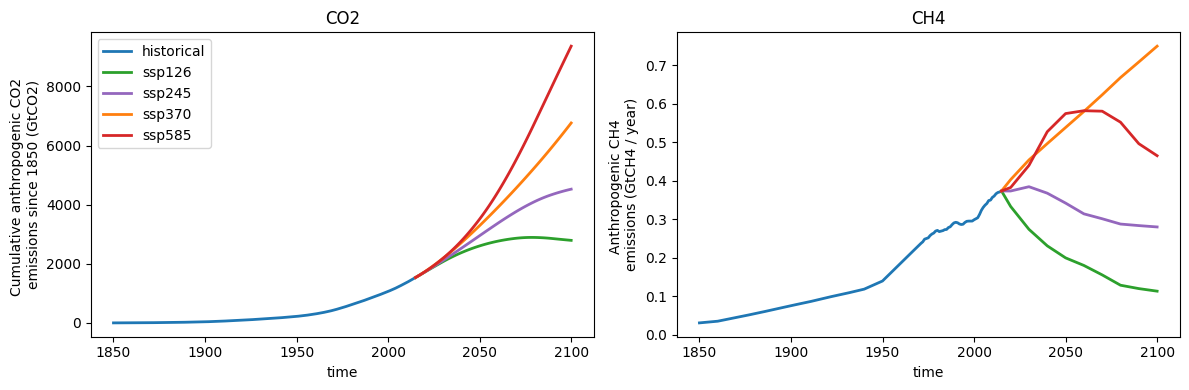

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
colors  = ['tab:blue','tab:green','tab:purple','tab:orange','tab:red']


for i,input in enumerate(inputs):

    label=input.split('_')[-1]#[:-3]
    X = open_dataset(input)
    x = X.time.data
    
    X['CO2'].plot(label=label,color=colors[i],linewidth=2,ax=axes[0])

    axes[0].set_ylabel("Cumulative anthropogenic CO2 \nemissions since 1850 (GtCO2)")
    
    X['CH4'].plot(label=label,color=colors[i],linewidth=2,ax=axes[1])

    axes[1].set_ylabel("Anthropogenic CH4 \nemissions (GtCH4 / year)")
    
axes[0].set_title('CO2')
axes[1].set_title('CH4')
axes[0].legend()
plt.tight_layout()

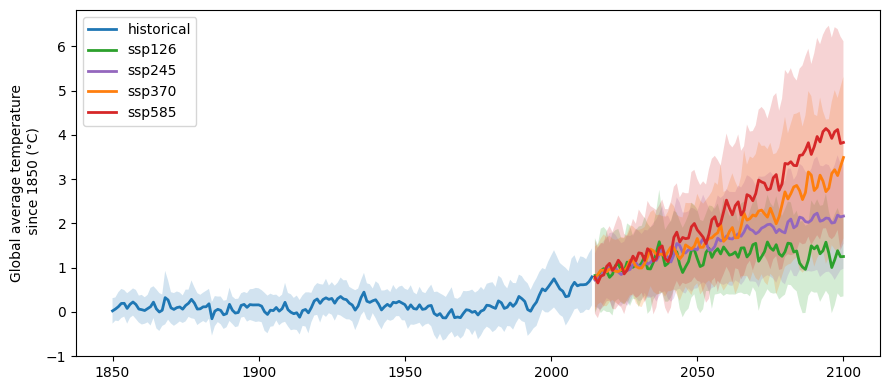

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(9,4))

for i,output in enumerate(outputs):

    label=output.split('_')[-1]#[:-3]
    X = open_dataset(output).mean(dim="member")[['tas']].drop_vars(['quantile'])
    x = X.time.data
    
    weights  = np.cos(np.deg2rad(X.lat))
    tas_mean = X['tas'].weighted(weights).mean(['lat', 'lon']).data
    tas_std  = X['tas'].weighted(weights).std(['lat', 'lon']).data
    
    ax.plot(x, tas_mean, label=label,color=colors[i],linewidth=2)
    ax.fill_between(x,tas_mean+tas_std,tas_mean-tas_std,facecolor=colors[i],alpha=0.2)
    
ax.set_ylabel("Global average temperature\n since 1850 (°C)")
ax.legend()
plt.tight_layout()

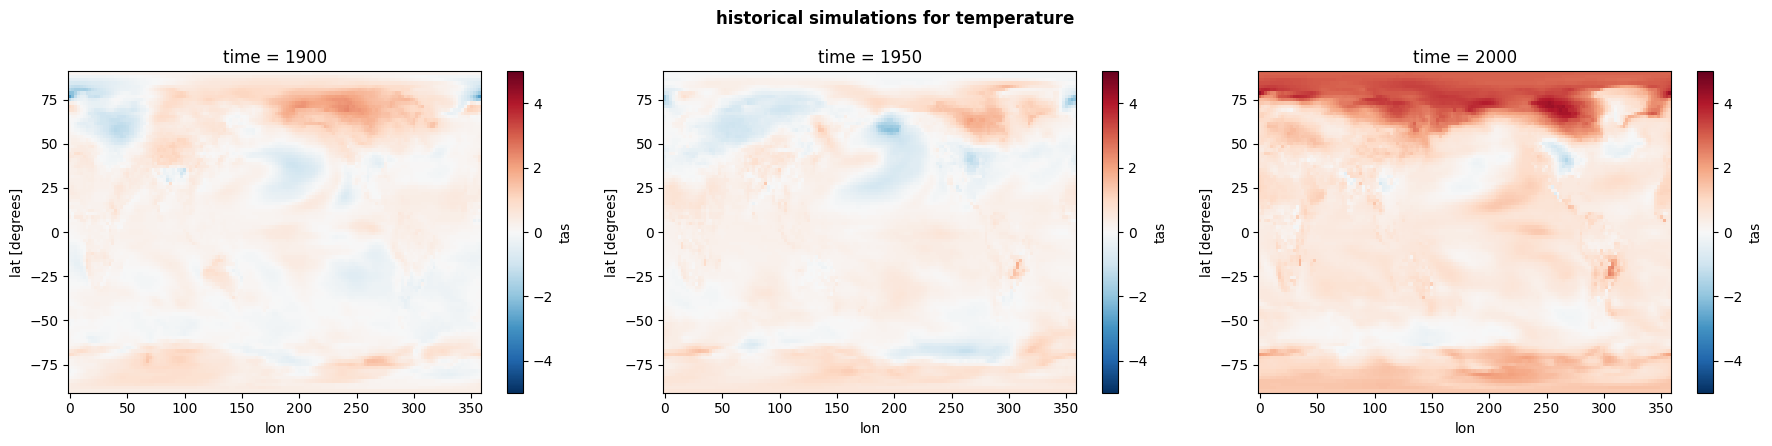

In [7]:
y_his    = open_dataset(os.path.join(train_path , "outputs_historical")).mean(dim="member")[['tas']].drop_vars(['quantile'])
y_ssp370 = open_dataset(os.path.join(train_path,'outputs_ssp370')).mean(dim="member")[['tas']].drop_vars(['quantile'])

fig,axes = plt.subplots(figsize=(18,4.5),ncols=3)
yr0, yr1, yr2 = 1900, 1950, 2000
vmin, vmax = -5, 5

y_his.sel(time=yr0).tas.plot(ax=axes.flat[0],vmin=vmin,vmax=vmax,cmap='RdBu_r')
y_his.sel(time=yr1).tas.plot(ax=axes.flat[1],vmin=vmin,vmax=vmax,cmap='RdBu_r')
y_his.sel(time=yr2).tas.plot(ax=axes.flat[2],vmin=vmin,vmax=vmax,cmap='RdBu_r')

fig.suptitle('historical simulations for temperature',fontweight='bold')
plt.tight_layout()

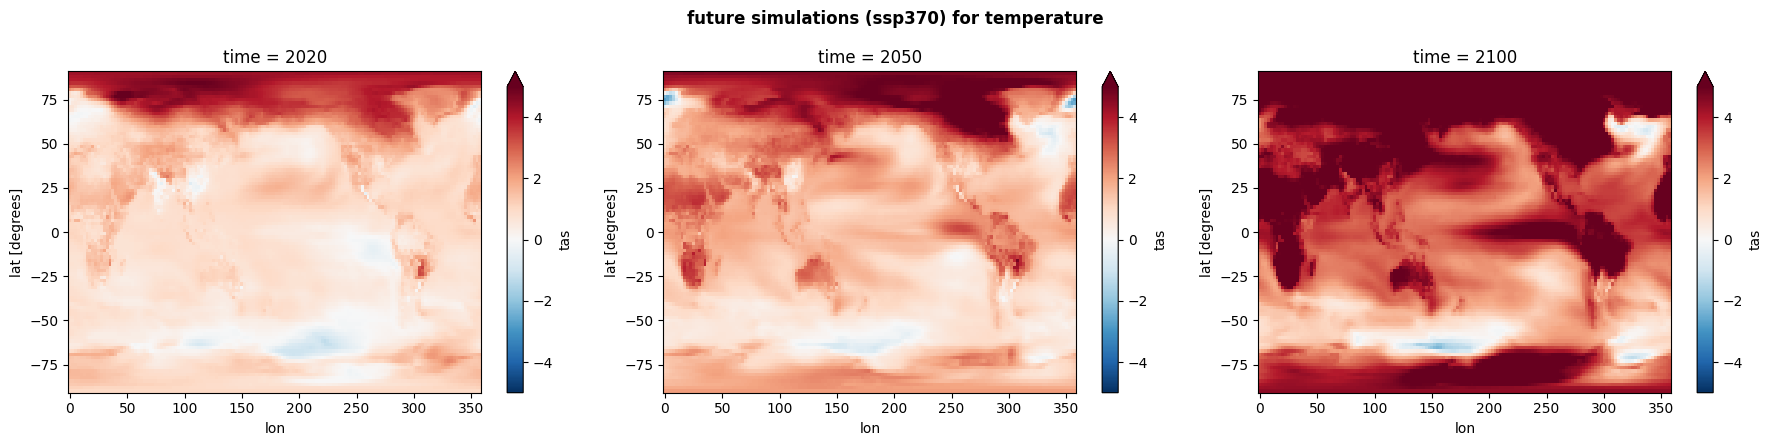

In [8]:
y_ssp370 = open_dataset(os.path.join(train_path,'outputs_ssp370')).mean(dim="member")[['tas']].drop_vars(['quantile'])


fig,axes = plt.subplots(figsize=(18,4.5),ncols=3)
yr0, yr1, yr2 = 2020, 2050, 2100
vmin, vmax = -5, 5

y_ssp370.sel(time=yr0).tas.plot(ax=axes.flat[0],vmin=vmin,vmax=vmax,cmap='RdBu_r')
y_ssp370.sel(time=yr1).tas.plot(ax=axes.flat[1],vmin=vmin,vmax=vmax,cmap='RdBu_r')
y_ssp370.sel(time=yr2).tas.plot(ax=axes.flat[2],vmin=vmin,vmax=vmax,cmap='RdBu_r')

fig.suptitle('future simulations (ssp370) for temperature',fontweight='bold')
plt.tight_layout()

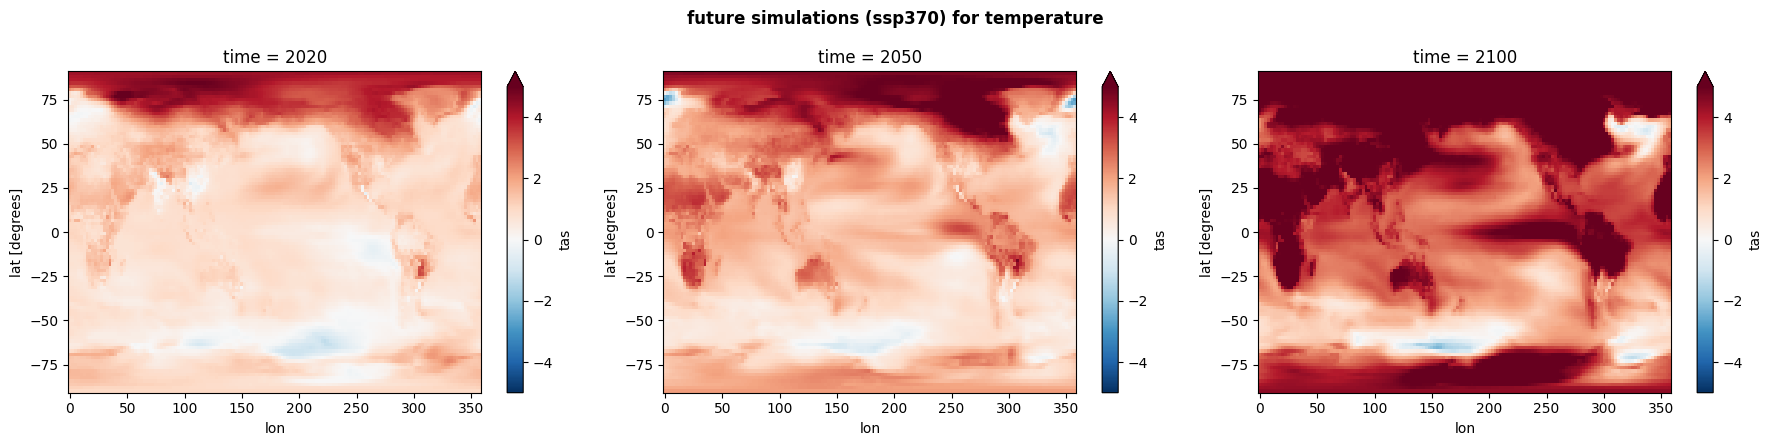

In [9]:
y_ssp370 = open_dataset(os.path.join(train_path,'outputs_ssp370')).mean(dim="member")[['tas']].drop_vars(['quantile'])


fig,axes = plt.subplots(figsize=(18,4.5),ncols=3)
yr0, yr1, yr2 = 2020, 2050, 2100
vmin, vmax = -5, 5

y_ssp370.sel(time=yr0).tas.plot(ax=axes.flat[0],vmin=vmin,vmax=vmax,cmap='RdBu_r')
y_ssp370.sel(time=yr1).tas.plot(ax=axes.flat[1],vmin=vmin,vmax=vmax,cmap='RdBu_r')
y_ssp370.sel(time=yr2).tas.plot(ax=axes.flat[2],vmin=vmin,vmax=vmax,cmap='RdBu_r')

fig.suptitle('future simulations (ssp370) for temperature',fontweight='bold')
plt.tight_layout()

## Data preprocessing
We will train the CNN using simulations from 3 historical and 3 future scenarios. We will then test the trained CNN on the ssp245 scenario.

In [10]:
def prepare_predictor(data_sets, data_path,time_reindex=True):
    """
    Args:
        data_sets list(str): names of datasets
    """
        
    # Create training and testing arrays
    if isinstance(data_sets, str):
        data_sets = [data_sets]
        
    X_all      = []
    length_all = []
    
    for file in data_sets:
        data = open_dataset(f"{data_path}inputs_{file}")
        X_all.append(data)
        length_all.append(len(data.time))
    
    X = xr.concat(X_all,dim='time')
    length_all = np.array(length_all)

    if time_reindex:
        X = X.assign_coords(time=np.arange(len(X.time)))

    return X, length_all
def prepare_predictand(data_sets,data_path,time_reindex=True):
    if isinstance(data_sets, str):
        data_sets = [data_sets]
        
    Y_all = []
    length_all = []
    
    for file in data_sets:
        data = open_dataset(f"{data_path}outputs_{file}")
        Y_all.append(data)
        length_all.append(len(data.time))
    
    length_all = np.array(length_all)
    Y = xr.concat(Y_all,dim='time').mean('member')
    Y = Y.rename({'lon':'longitude','lat': 'latitude'}).transpose('time','latitude', 'longitude').drop_vars(['quantile'])
    if time_reindex:
        Y = Y.assign_coords(time=np.arange(len(Y.time)))
    
    return Y, length_all

In [11]:
# Training set
train_files    = ["historical", "ssp585", "ssp126", "ssp370","hist-aer","hist-GHG"]
X_train_xr, _  = prepare_predictor(train_files,train_path)
y_train_xr, _  = prepare_predictand(train_files,train_path)

# Test set
X_test_xr, _ = prepare_predictor('ssp245', data_path=test_path,time_reindex=False)
y_test_xr, _ = prepare_predictand('ssp245',data_path=test_path,time_reindex=False)

## Inputs and targets for the CNN
The CNN takes the two predictors for one year, CO2 and CH4, and outputs the global temperature map for that year. We put the predictors into a table with one row per year.

In [12]:
X_train_df = pd.DataFrame({"CO2": X_train_xr["CO2"].data,
                           "CH4": X_train_xr["CH4"].data
                          }, index=X_train_xr["CO2"].coords['time'].data)

X_test_df  = pd.DataFrame({"CO2": X_test_xr["CO2"].data,
                           "CH4": X_test_xr["CH4"].data
                          }, index=X_test_xr["CO2"].coords['time'].data)

y_train = y_train_xr['tas'].data
y_test  = y_test_xr['tas'].data

The target (predictand) for each year is a 2-D map of global temperature, 96 latitudes by 144 longitudes. It stays a map, because the CNN builds its output as a map.

## Data Normalization

Let's normalize the input predictors by their mean and standard deviation.

In [13]:
	# Standardization
mean, std = X_train_df.mean(), X_train_df.std()

X_train_df   = (X_train_df - mean)/std
X_test_df    = (X_test_df - mean)/std

X_train = X_train_df.to_numpy()
X_test = X_test_df.to_numpy()

In [14]:
print(X_train.shape,y_train.shape,X_test.shape,y_test.shape)

(753, 2) (753, 96, 144) (86, 2) (86, 96, 144)


## Define the CNN architecture

The CNN architecture used here consists of several upsampling layers. 

We set the dimensions of the hidden layers (i.e., number of neurons) in order to reach the size of the target maps (96x144) in a proportional way (in particular by doubling the dimensions in each upsampling layer) through the various upsampling layers.

Here are the hyperparameters for the CNN training. Note that these hyperparameters here are for demonstration purposes only and they are not optimized.

In [15]:
n_filters  = 32  # number of filters
n_neurons  = 32  # number of neurons in the Dense layer
activation     = 'relu' # activation function
kernel_size    = 4
learning_rate  = 0.001
minibatch_size = 64
num_epochs     = 100

In [16]:
model = Sequential()


model.add(Input(shape=(X_train.shape[1],))),
model.add(Dense(n_filters*12*18, input_shape=(X_train.shape[1],), activation=activation)) # shape: (6912,1)
model.add(Reshape((12,18,n_filters))) # shape: (12,18,32)

# Upsample to 24x36
model.add(Conv2DTranspose(filters=n_filters, kernel_size=kernel_size, 
                          activation=activation, strides=2, padding='same')) # shape: (24,36,32)

# Upsample to 48x72
model.add(Conv2DTranspose(filters=n_filters, kernel_size=kernel_size, 
                          activation=activation, strides=2, padding='same')) # shape: (48,72,32)

# Upsample to 96x144
model.add(Conv2DTranspose(filters=n_filters, kernel_size=kernel_size, 
                          activation=activation, strides=2, padding='same')) # shape: (96,144,32)

model.add(Conv2DTranspose(filters=1, kernel_size=kernel_size, activation="linear", padding="same")) # shape: (96,144,1)


model.summary()
model.compile(loss='mse',optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate))

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 6912)              20736     
                                                                 
 reshape (Reshape)           (None, 12, 18, 32)        0         
                                                                 
 conv2d_transpose (Conv2DTra  (None, 24, 36, 32)       16416     
 nspose)                                                         
                                                                 
 conv2d_transpose_1 (Conv2DT  (None, 48, 72, 32)       16416     
 ranspose)                                                       
                                                                 
 conv2d_transpose_2 (Conv2DT  (None, 96, 144, 32)      16416     
 ranspose)                                                       
                                                        

## Train and save the CNN model

In [17]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=20)


history_cnn = model.fit(X_train, y_train, 
                    batch_size      = minibatch_size,
                    epochs          = num_epochs,
                    validation_split= 0.2, 
                    verbose         = 1,
                    callbacks       = [early_stop])

Epoch 1/100
10/10 [==============================] - 2s 130ms/step - loss: 3.6434 - val_loss: 0.4700
Epoch 2/100
10/10 [==============================] - 1s 119ms/step - loss: 2.5274 - val_loss: 0.5913
Epoch 3/100
10/10 [==============================] - 1s 122ms/step - loss: 1.5080 - val_loss: 0.2634
Epoch 4/100
10/10 [==============================] - 1s 120ms/step - loss: 0.8821 - val_loss: 0.2616
Epoch 5/100
10/10 [==============================] - 1s 120ms/step - loss: 0.7113 - val_loss: 0.2702
Epoch 6/100
10/10 [==============================] - 1s 120ms/step - loss: 0.6297 - val_loss: 0.2604
Epoch 7/100
10/10 [==============================] - 1s 122ms/step - loss: 0.5814 - val_loss: 0.2454
Epoch 8/100
10/10 [==============================] - 1s 119ms/step - loss: 0.5501 - val_loss: 0.2464
Epoch 9/100
10/10 [==============================] - 1s 118ms/step - loss: 0.5258 - val_loss: 0.2442
Epoch 10/100
10/10 [==============================] - 1s 120ms/step - loss: 0.5067 - val_lo

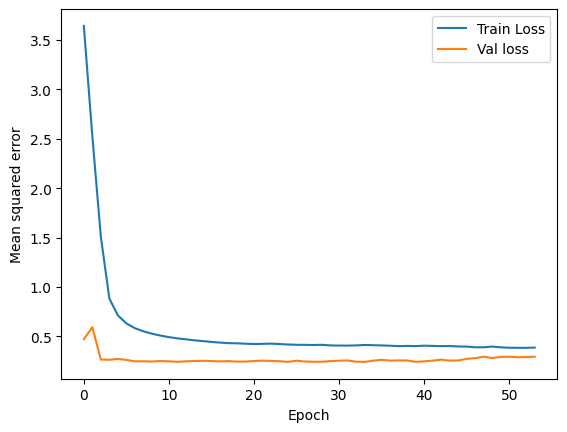

In [18]:
plt.figure()
plt.xlabel('Epoch')
plt.ylabel('Mean squared error')
plt.plot(history_cnn.epoch, np.array(history_cnn.history['loss']),label='Train Loss')
plt.plot(history_cnn.epoch, np.array(history_cnn.history['val_loss']),label = 'Val loss')
plt.legend()

In [19]:
model_path = os.path.join(cwd,'saved_model')
if os.path.exists(model_path) is False:
    os.makedirs(model_path)

In [20]:
# Save the entire model to a HDF5 file.
# The '.h5' extension indicates that the model should be saved to HDF5.
model.save(os.path.join(model_path,'CNN_model.keras'))

## Evaluate the trained model

We will load the model since it takes a while to train.

In [21]:
# reload the saved model
model = load_model(os.path.join(model_path,'CNN_model.keras'))

In [22]:
y_test_pre = model.predict(X_test)
y_test_pre = y_test_pre.reshape(y_test_pre.shape[0], 96, 144)
y_test_pre = xr.Dataset(coords={'time': X_test_xr.time.values, 
                               'latitude': X_test_xr.latitude.values, 
                               'longitude': X_test_xr.longitude.values},
                       data_vars=dict(tas=(['time', 'latitude', 'longitude'], y_test_pre)))

3/3 [==============================] - 0s 21ms/step


First we check whether the ML model can capture the spatial distribution of global temperature

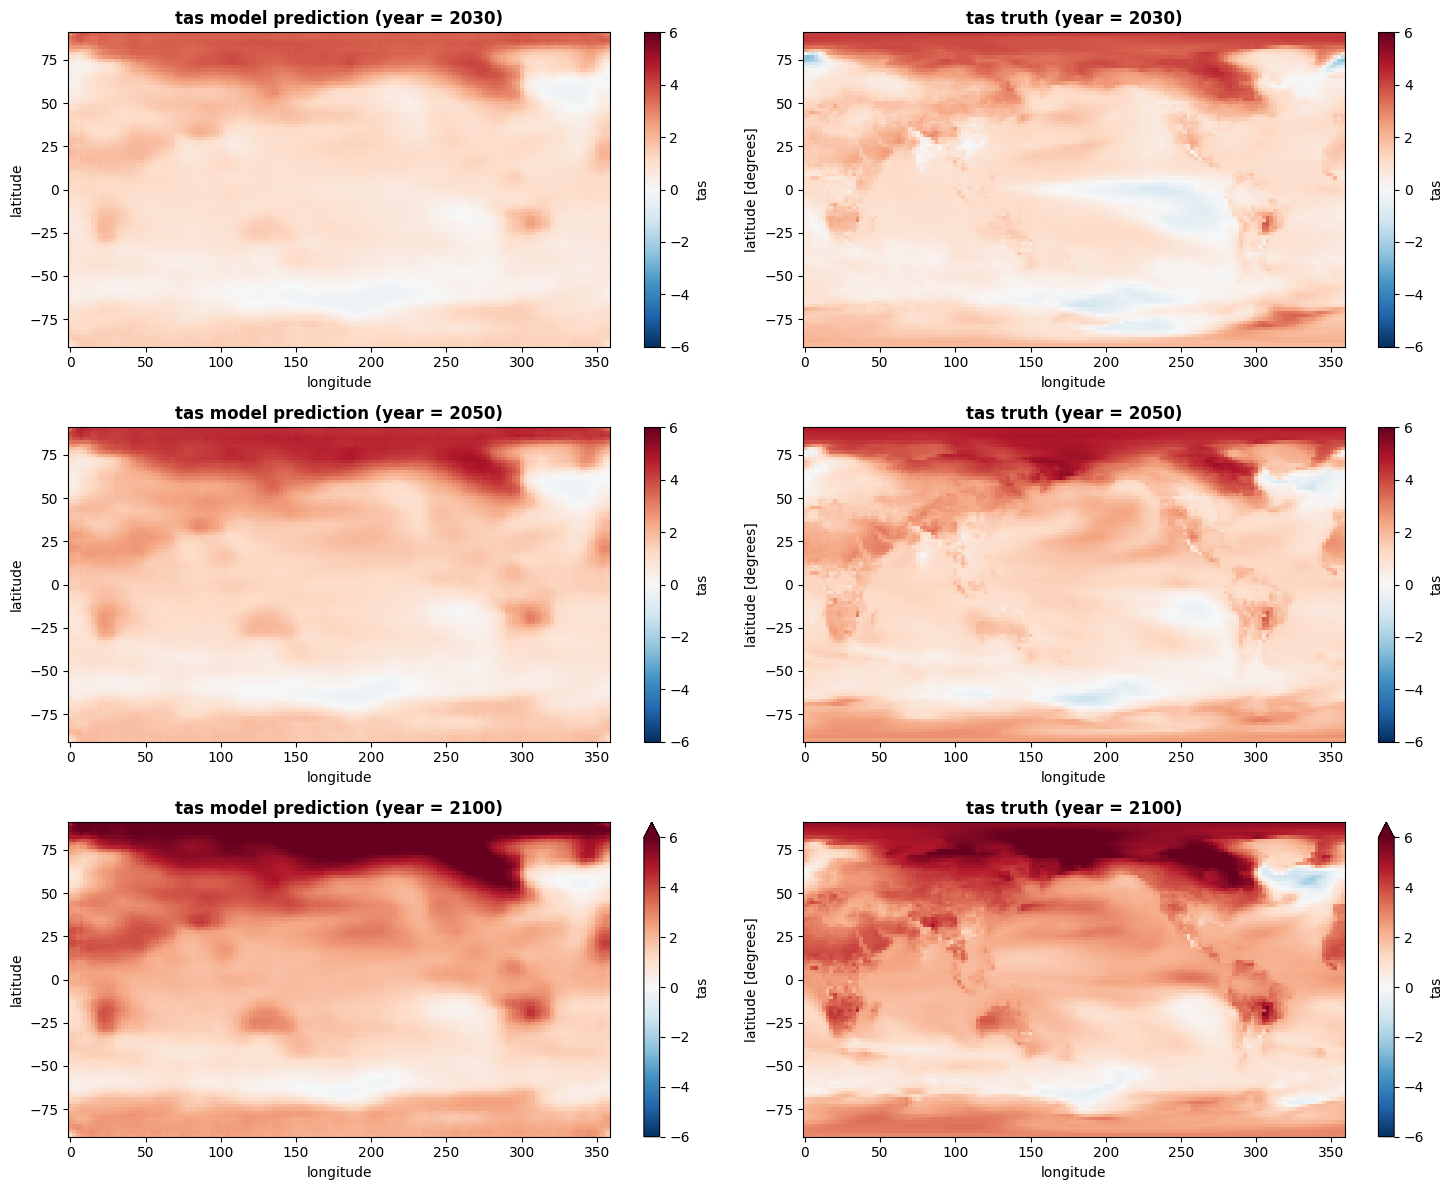

In [23]:
fig, axes = plt.subplots(figsize=(15,12),ncols=2,nrows=3)

yrs = [2030, 2050, 2100]
vmin, vmax    = -6, 6
cmap = 'RdBu_r'
y_test_pre.tas.sel(time=yrs[0]).plot(ax=axes[0,0], vmin=vmin, vmax=vmax,cmap=cmap)
y_test_xr.tas.sel(time=yrs[0]).plot(ax=axes[0,1], vmin=vmin, vmax=vmax,cmap=cmap)

y_test_pre.tas.sel(time=yrs[1]).plot(ax=axes[1,0], vmin=vmin, vmax=vmax,cmap=cmap)
y_test_xr.tas.sel(time=yrs[1]).plot(ax=axes[1,1], vmin=vmin, vmax=vmax,cmap=cmap)

y_test_pre.tas.sel(time=yrs[2]).plot(ax=axes[2,0], vmin=vmin, vmax=vmax,cmap=cmap)
y_test_xr.tas.sel(time=yrs[2]).plot(ax=axes[2,1], vmin=vmin, vmax=vmax,cmap=cmap)


for i, ax in enumerate(axes.flat):
    # left column: model prediction
    if i % 2 == 0:
        ax.set_title(f'tas model prediction (year = {yrs[i//2]})',fontweight='bold')
    # right column: truth tas from ssp245 simulations
    else:
        ax.set_title(f'tas truth (year = {yrs[i//2]})',fontweight='bold')
plt.tight_layout()

Then we also check whether the ML model can reproduce the time series of a given location.
Here we take NYC as an example (40.7128° N, 74.0060° W)

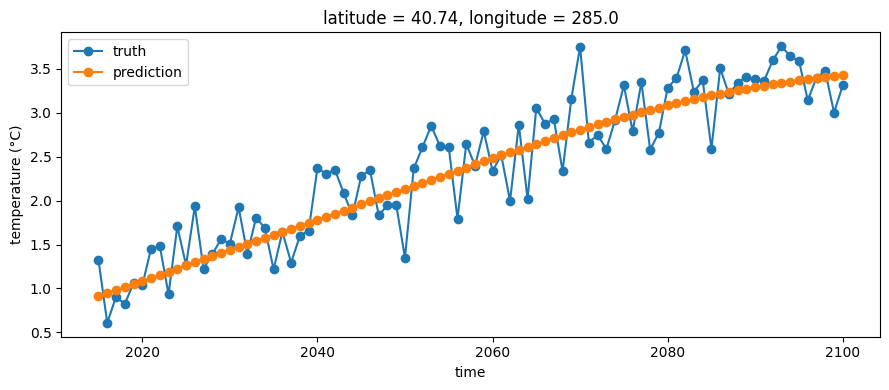

In [24]:
lat = 40.7128
lon = -74.0060%360

fig,ax = plt.subplots(figsize=(9,4))
y_test_xr.sel(latitude=lat,longitude=lon,method='nearest').tas.plot(marker='o',ax=ax,label='truth')
y_test_pre.sel(latitude=lat,longitude=lon,method='nearest').tas.plot(marker='o',ax=ax,label='prediction')

ax.legend()
ax.set_ylabel('temperature (°C)')

plt.tight_layout()

Finally we will check whether the ML model can capture the time series of global average temperatures. 

In [25]:
def global_mean_std_plot(X,label,color,ax,var='tas'):
    weights  = np.cos(np.deg2rad(X.latitude))
    tas_mean = X[var].weighted(weights).mean(['latitude', 'longitude']).data
    tas_std  = X[var].weighted(weights).std(['latitude', 'longitude']).data
    
    x = X.time.data

    ax.plot(x, tas_mean, label=label,color=color,linewidth=2)
    ax.fill_between(x,tas_mean+tas_std,tas_mean-tas_std,facecolor=color,alpha=0.2)

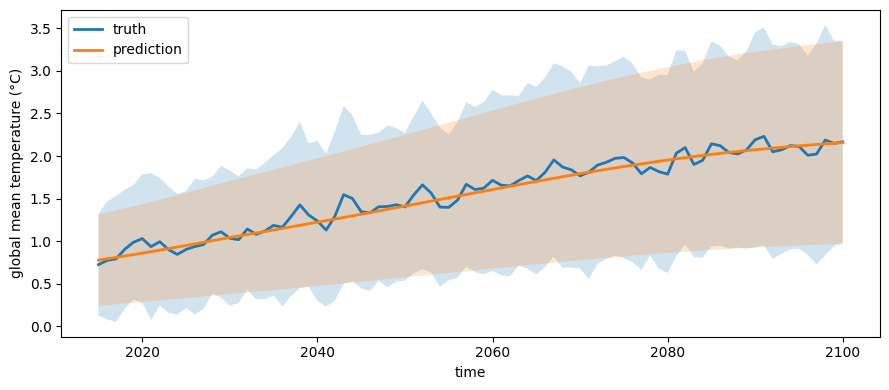

In [26]:
fig,ax = plt.subplots(figsize=(9,4))

global_mean_std_plot(y_test_xr,label='truth',ax=ax,color='tab:blue')
global_mean_std_plot(y_test_pre,label='prediction',ax=ax,color='tab:orange')

ax.set_xlabel('time')
ax.set_ylabel('global mean temperature (°C)')
ax.legend()
plt.tight_layout()

## Try it yourself

1. **Set the random seed.** The CNN starts from random weights (and SGD samples random batches), so results shift slightly run to run. Add `tf.random.set_seed(42)` before building the model and confirm the losses reproduce.
2. **Test on a different scenario.** Retrain on the other scenarios and test on **ssp585** instead of ssp245. Does the emulator do worse when it has to *extrapolate* to a hotter scenario than any it trained on, rather than *interpolate*?
3. **Tune the CNN.** Try a larger `kernel_size`, more `n_filters`, or more up-sampling layers. Can you sharpen the blurry maps without overfitting the small dataset?
4. **Add a metric.** Pass `metrics=['RootMeanSquaredError']` to `model.compile` and watch the RMSE (in °C) alongside the MSE loss during training.

The last two run in seconds and neither retrains a model, so they are good to try in class if there is time.

5. **Read off the architecture, no training.** Rebuild *only* the CNN (the `Sequential()` cell) with a different `kernel_size` (try 3 and 8) or a different `n_filters`, then call `model.summary()`. Do **not** call `model.fit`. The output stays 96 by 144 whatever the filter size: why? (Look at `padding='same'` and the three stride-2 up-sampling layers.) How does the total parameter count change as you enlarge the filters or add more of them? For comparison, a dense network that passes the two inputs through three hidden layers of 64 neurons to one output neuron per grid cell has about 907,000 weights.
6. **Which data augmentations suit a climate map?** The lecture introduced data augmentation (rotations, flips, translations, resizing) as a way to expand an image dataset when you do not have enough of it. For a global surface-temperature map on a latitude/longitude grid, which of these give a *physically plausible* new training example and which do not? Think about flipping the map north to south (swapping the hemispheres), rolling it in longitude (shifting the prime meridian), or rotating it 90 degrees (mixing latitude with longitude). No code required, just reason it through.